In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import seaborn as sns
sns.set()

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN

In [15]:
train = np.load("Z_train.npy")
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train)

##### KMeans

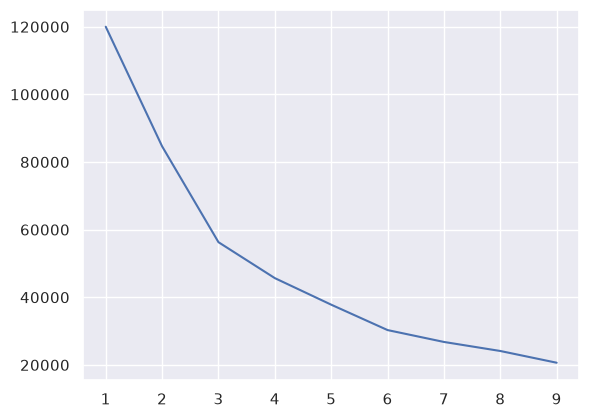

In [16]:
WCSS = []
for i in range(1,10):
    kmeans = KMeans(n_clusters=i,init="k-means++")
    kmeans.fit(train_scaled)
    WCSS.append(kmeans.inertia_)

plt.plot(range(1,10),WCSS)


Using the elbow method we can see that the number of clusters that we can use here is 3

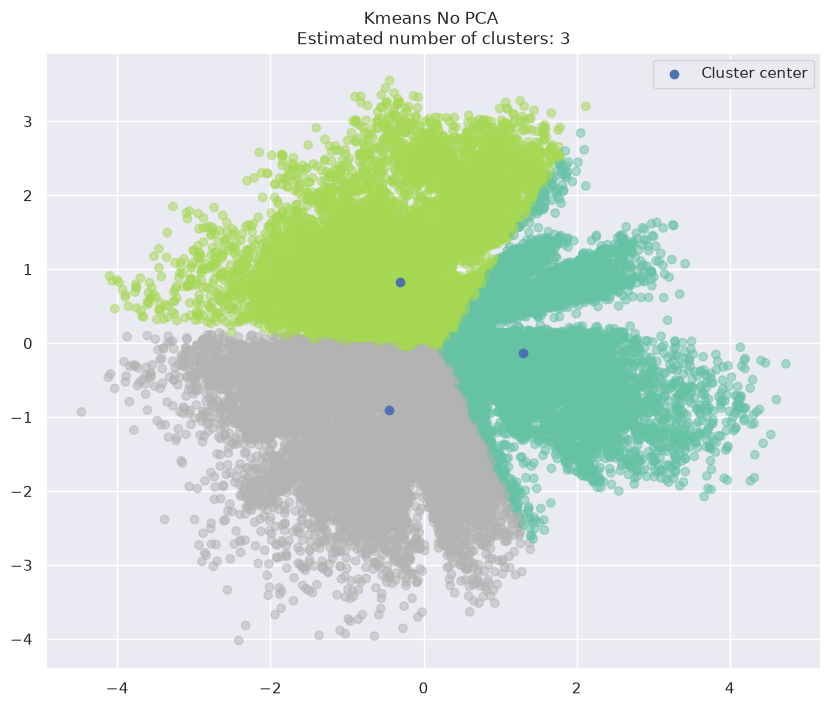

In [37]:
kmeans = KMeans(n_clusters=3,init="k-means++")
kmeans.fit(train_scaled)
labels = kmeans.predict(train_scaled)

x = train_scaled[:,0]
y = train_scaled[:,1]
plt.figure(figsize=(10,8))
plt.scatter(x,y,c=labels,cmap="Set2",alpha=0.5)

center = kmeans.cluster_centers_
center_x = center[:,0]
center_y = center[:,1]

plt.scatter(center_x,center_y,label="Cluster center")
plt.title(f"Kmeans No PCA \nEstimated number of clusters: 3")
plt.legend()
plt.show()

##### Kmeans with PCA